# Exercício 1 — Valores Ausentes
## Melbourne Housing Snapshot

### IMPORTAÇÕES

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

### CARREGAMENTO DOS DADOS E DIAGNÓSTICO INICIAL

In [16]:
df = pd.read_csv("../data/melb_data.csv")

print(df.head())
print(df.shape)

       Suburb           Address  Rooms Type      Price Method SellerG  \
0  Abbotsford      85 Turner St      2    h  1480000.0      S  Biggin   
1  Abbotsford   25 Bloomburg St      2    h  1035000.0      S  Biggin   
2  Abbotsford      5 Charles St      3    h  1465000.0     SP  Biggin   
3  Abbotsford  40 Federation La      3    h   850000.0     PI  Biggin   
4  Abbotsford       55a Park St      4    h  1600000.0     VB  Nelson   

        Date  Distance  Postcode  ...  Bathroom  Car  Landsize  BuildingArea  \
0  3/12/2016       2.5    3067.0  ...       1.0  1.0     202.0           NaN   
1  4/02/2016       2.5    3067.0  ...       1.0  0.0     156.0          79.0   
2  4/03/2017       2.5    3067.0  ...       2.0  0.0     134.0         150.0   
3  4/03/2017       2.5    3067.0  ...       2.0  1.0      94.0           NaN   
4  4/06/2016       2.5    3067.0  ...       1.0  2.0     120.0         142.0   

   YearBuilt  CouncilArea Lattitude  Longtitude             Regionname  \
0     

In [ ]:
# Tipo de cada coluna
df.dtypes

Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

### RESUMO DE VALORES AUSENTES (QUANTIDADE E %)

In [ ]:
# Número de valores nulos em cada coluna
df.isnull().sum()

Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
Lattitude           0
Longtitude          0
Regionname          0
Propertycount       0
dtype: int64

In [ ]:
# Percentual de valores nulos em cada coluna
(df.isnull().mean() * 100).sort_values(ascending=False)

BuildingArea     47.496318
YearBuilt        39.580265
CouncilArea      10.081001
Car               0.456554
Suburb            0.000000
Price             0.000000
Type              0.000000
Rooms             0.000000
Address           0.000000
Distance          0.000000
Method            0.000000
Date              0.000000
SellerG           0.000000
Bathroom          0.000000
Bedroom2          0.000000
Postcode          0.000000
Landsize          0.000000
Lattitude         0.000000
Longtitude        0.000000
Regionname        0.000000
Propertycount     0.000000
dtype: float64

### VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA

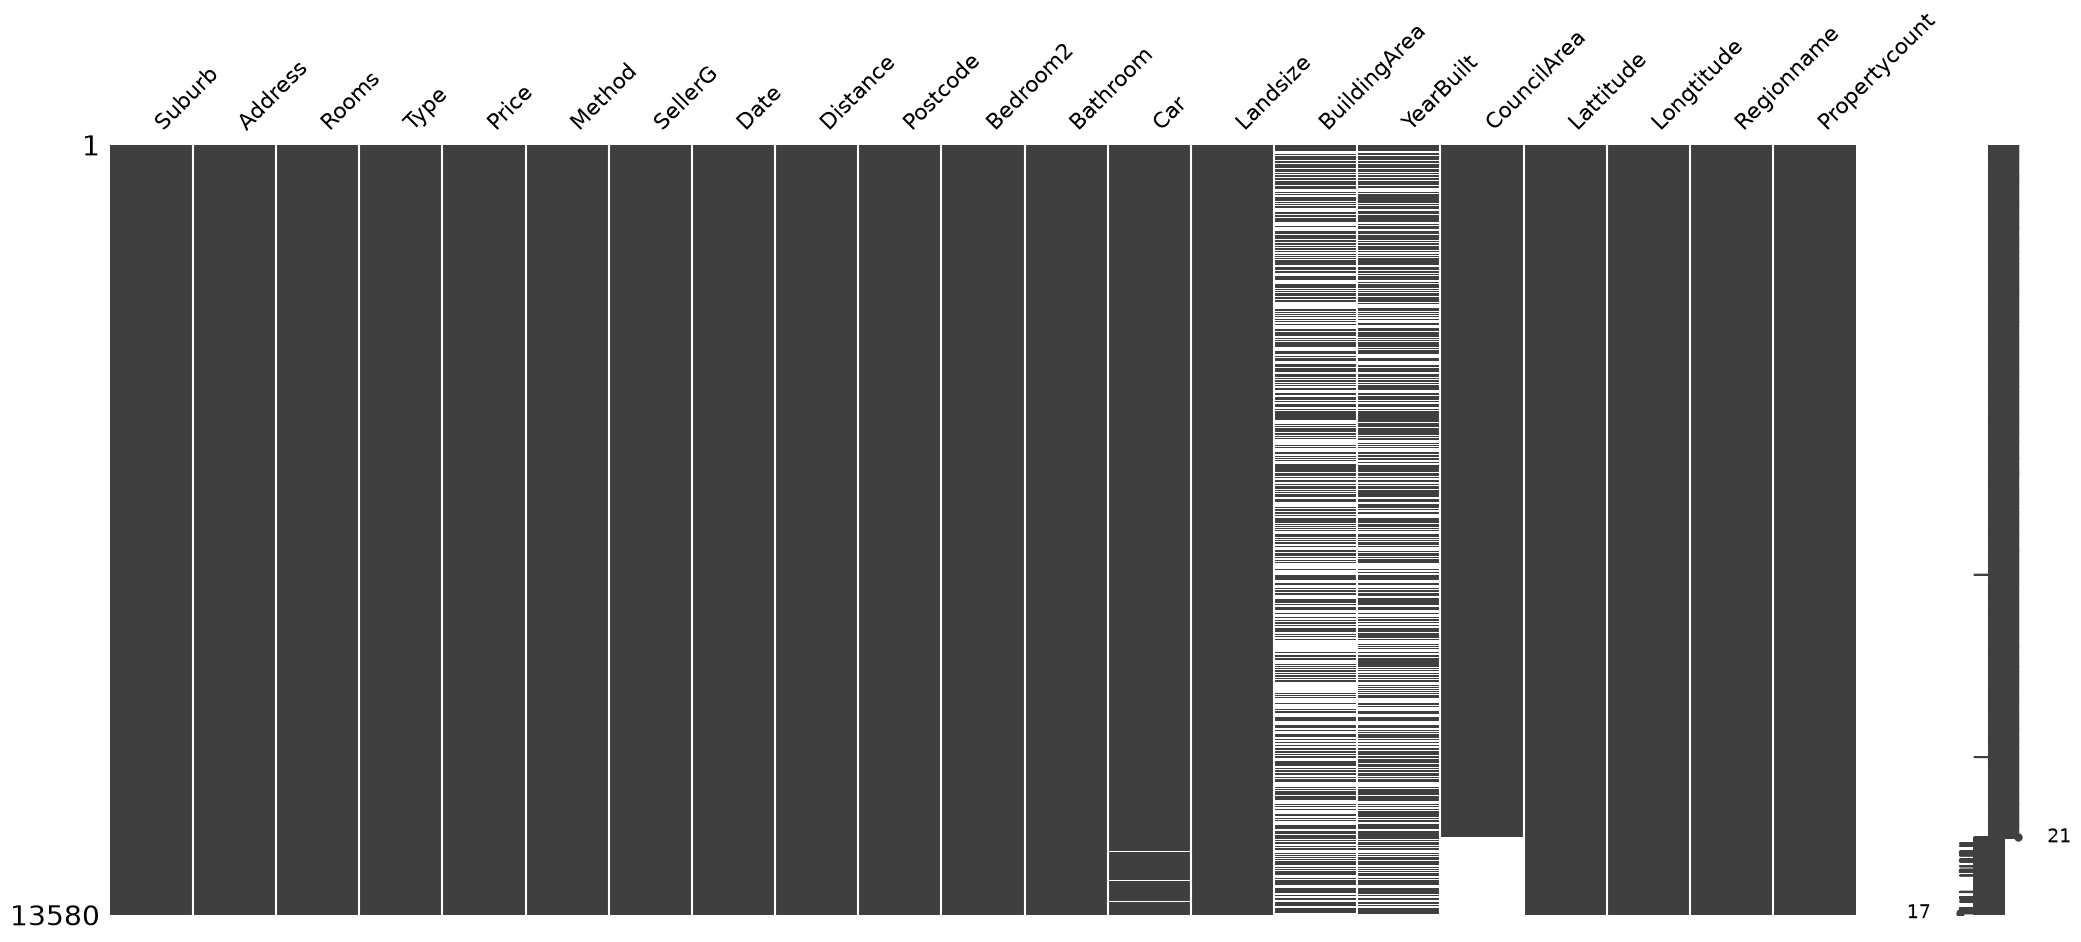

In [15]:
msno.matrix(df)
plt.show()

### ESTRATÉGIA 1 — REMOÇÃO

In [19]:
df_remocao = df.dropna().copy()
print("Valores ausentes restantes:", df_remocao.isnull().sum().sum())

Valores ausentes restantes: 0


### ESTRATÉGIA 2 — IMPUTAÇÃO

In [20]:
df_imputacao = df.copy()

# Colunas numéricas: preencher com a mediana
colunas_numericas = ["Car", "BuildingArea", "YearBuilt"]

for coluna in colunas_numericas:
    df_imputacao[coluna] = df_imputacao[coluna].fillna(
        df_imputacao[coluna].median()
    )

# Coluna categórica: preencher com a moda
moda_council = df_imputacao["CouncilArea"].mode()

if not moda_council.empty:
    df_imputacao["CouncilArea"] = df_imputacao["CouncilArea"].fillna(
        moda_council.iloc[0]
    )

print("Valores ausentes restantes:", df_remocao.isnull().sum().sum())

Valores ausentes restantes: 0


### COMPARAÇÃO ENTRE AS ESTRATÉGIAS

In [21]:
print("Dataset original:", df.shape)
print("Após remoção:", df_remocao.shape)
print("Após imputação:", df_imputacao.shape)

Dataset original: (13580, 21)
Após remoção: (6196, 21)
Após imputação: (13580, 21)


### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada?**

   Uma coluna com muitos valores ausentes não precisa ser descartada automaticamente. A decisão depende da importância da informação para a análise e da quantidade de dados que ainda está disponível. Se a coluna for pouco relevante, pode ser melhor removê-la. Porém, se for importante para o estudo, podemos tentar imputar os valores ou investigar por que estão ausentes.

2. **Para colunas como Price ou Landsize, média e mediana dariam valores parecidos? Qual seria mais segura, e por quê?**

   Não necessariamente. Essas colunas podem apresentar valores muito altos ou muito baixos em comparação com a maioria dos registros, o que influencia a média. A mediana costuma ser mais segura nesses casos, pois é menos afetada por valores extremos e representa melhor o centro dos dados quando a distribuição é assimétrica. Se os dados tiverem uma distribuição equilibrada e poucos valores extremos, a média e a mediana podem ser parecidas.

3. **Em que situação o fato de um valor estar ausente é, por si só, uma informação útil para a análise?**

   A ausência pode indicar alguma característica importante do registro. Por exemplo, se o ano de construção (`YearBuilt`) estiver ausente com maior frequência em imóveis antigos, isso pode revelar um padrão nos dados. Da mesma forma, se o preço estiver ausente em determinados tipos de imóveis, essa ausência pode estar relacionada à forma como os dados foram coletados. Nesses casos, vale analisar o padrão das ausências e até criar uma coluna indicadora para registrar quais valores estavam ausentes antes da imputação.

### DESAFIO

In [24]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

colunas_knn = ["Car", "BuildingArea", "YearBuilt"]
df_knn = df.copy()

scaler = StandardScaler()
X = df[colunas_knn]

# Padronizar as escalas
X_scaled = scaler.fit_transform(X)

# Imputar utilizando os 5 vizinhos mais próximos
knn = KNNImputer(n_neighbors=5)
X_imputado = knn.fit_transform(X_scaled)

# Retornar à escala original
X_original = scaler.inverse_transform(X_imputado)

df_knn[colunas_knn] = X_original

coluna = "BuildingArea"

comparacao = pd.DataFrame({
    "Original": df[coluna].agg(["mean", "median"]),
    "Mediana": df_imputacao[coluna].agg(["mean", "median"]),
    "KNN": df_knn[coluna].agg(["mean", "median"])
})

print(comparacao.round(2))

        Original  Mediana     KNN
mean      151.97   139.63  153.35
median    126.00   126.00  130.00


# Exercício 2 — Duplicatas
## Customer Transaction Dataset (KPMG)

### CARREGAMENTO DE DADOS

In [14]:
df = pd.read_excel("../data/KPMG_VI_New_raw_data_update_final.xlsx", sheet_name="Transactions", header=1)
df.head()

,transaction_id,product_id,customer_id,transaction_date,online_order,order_status,brand,product_line,product_class,product_size,list_price,standard_cost,product_first_sold_date
0,1,2,2950,2017-02-25,0.0,Approved,Solex,Standard,medium,medium,71.49,53.62,41245.0
1,2,3,3120,2017-05-21,1.0,Approved,Trek Bicycles,Standard,medium,large,2091.47,388.92,41701.0
2,3,37,402,2017-10-16,0.0,Approved,OHM Cycles,Standard,low,medium,1793.43,248.82,36361.0
3,4,88,3135,2017-08-31,0.0,Approved,Norco Bicycles,Standard,medium,medium,1198.46,381.10,36145.0
4,5,78,787,2017-10-01,1.0,Approved,Giant Bicycles,Standard,medium,large,1765.30,709.48,42226.0


### CONFERÊNCIA DO CABEÇALHO E DOS TIPOS

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   transaction_id           20000 non-null  int64         
 1   product_id               20000 non-null  int64         
 2   customer_id              20000 non-null  int64         
 3   transaction_date         20000 non-null  datetime64[ns]
 4   online_order             19640 non-null  float64       
 5   order_status             20000 non-null  object        
 6   brand                    19803 non-null  object        
 7   product_line             19803 non-null  object        
 8   product_class            19803 non-null  object        
 9   product_size             19803 non-null  object        
 10  list_price               20000 non-null  float64       
 11  standard_cost            19803 non-null  float64       
 12  product_first_sold_date  19803 n

In [15]:
df.dtypes

transaction_id                      int64
product_id                          int64
customer_id                         int64
transaction_date           datetime64[ns]
online_order                      float64
order_status                       object
brand                              object
product_line                       object
product_class                      object
product_size                       object
list_price                        float64
standard_cost                     float64
product_first_sold_date           float64
dtype: object

### DUPLICATAS EXATAS

In [20]:
df.duplicated().sum()

np.int64(0)

### DUPLICATAS POR SUBCONJUNTO DE COLUNAS

In [ ]:
df.duplicated(subset=['transaction_id', 'customer_id']).sum()
# transaction_id deve ser único se cada linha representa uma transação.

np.int64(0)

### UNICIDADE DOS IDENTIFICADORES

In [28]:
for coluna in ["transaction_id", "customer_id"]:
    if coluna in df.columns:
        print(f"\nColuna: {coluna}")
        print("Valores distintos:", df[coluna].nunique())
        print("Valores ausentes:", df[coluna].isna().sum())
        print(
            "Linhas com identificador repetido:",
            df.duplicated(subset=[coluna], keep=False).sum()
        )


Coluna: transaction_id
Valores distintos: 20000
Valores ausentes: 0
Linhas com identificador repetido: 0

Coluna: customer_id
Valores distintos: 3494
Valores ausentes: 0
Linhas com identificador repetido: 19951


### ESTRATÉGIA DE TRATAMENTO E IMPACTO

A estratégia seria remover ou substituir pela moda, as duplicatas exatas e, depois, manter o registro de data mais recente para cada transaction_id preenchido. A diferença na soma de list_price mostra o impacto financeiro potencial da remoção. Ela não significa necessariamente que esse valor foi corrigido: isso depende de as linhas removidas serem de fato duplicatas indevidas.

### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **Se o resultado de duplicatas exatas for zero, isso garante que não há registros repetidos? Por quê?**

   Não. Podem existir registros que representam a mesma transação, mas apresentam diferenças em alguma coluna, como data, preço ou descrição.

2. **Em uma base de transações, duas linhas idênticas são sempre um erro? Dê um exemplo em que não seriam.**

   Não. Duas compras legítimas podem ter o mesmo cliente, produto, preço e data. Se não houver um identificador que as diferencie, elas podem parecer idênticas, embora representem operações diferentes.

3. **Por que a escolha das colunas que definem o mesmo registro é uma decisão de negócio, e não apenas técnica? Relacione com o CRISP-DM.**

   Porque é necessário compreender o significado de cada registro e as regras que definem uma transação única. No CRISP-DM, essa decisão está relacionada ao Entendimento do Negócio, pois os objetivos e as regras do processo determinam quais registros devem ser considerados duplicados.

### DESAFIO

In [34]:
from rapidfuzz import process, fuzz
# Identificar possíveis variações na coluna brand
if "brand" in df.columns:
    marcas = (
        df["brand"]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
        .tolist()
    )

    pares = set()

    for marca in marcas:
        resultados = process.extract(
            marca,
            marcas,
            scorer=fuzz.ratio,
            limit=5
        )

        for outra, pontuacao, _ in resultados:
            if marca != outra and pontuacao >= 85:
                pares.add(tuple(sorted([marca, outra])))

    for marca1, marca2 in sorted(pares):
        print(
            f"{marca1} | {marca2} | "
            f"Similaridade: {fuzz.ratio(marca1, marca2):.1f}"
        )
if pares:
    for marca1, marca2 in sorted(pares):
        print(
            f"{marca1} | {marca2} | "
            f"Similaridade: {fuzz.ratio(marca1, marca2):.1f}"
        )
else:
    print("Nenhuma variação de marca com similaridade >= 85% foi encontrada.")

Nenhuma variação de marca com similaridade >= 85% foi encontrada.


# Exercício 3 — Padronização e Escalonamento

## Adult Census Income

### IMPORTAÇÕES E NOMES DAS COLUNAS

In [35]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

In [36]:
colunas = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week",
    "native-country", "income"
]

### CARREGAMENTO DOS DADOS

In [37]:
df_adult = pd.read_csv(
    "../data/adult.data",
    header=None,
    names=colunas,
    skipinitialspace=True
)
df_adult.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
df_adult.info()

### INSPEÇÃO DAS COLUNAS CATEGÓRICAS

In [55]:
colunas_categoricas = df_adult.select_dtypes(include="object").columns.tolist()

for coluna in colunas_categoricas:
    valores = df_adult[coluna].dropna().unique()
    print(f"\n{coluna} — {len(valores)} categorias distintas")
    print(sorted(valores.tolist()))
    print("Valores com espaços nas extremidades:",
          sum(valor != valor.strip() for valor in valores))
    print("Marcadores ?:", df_adult[coluna].eq("?").sum())


workclass — 9 categorias distintas
['?', 'Federal-gov', 'Local-gov', 'Never-worked', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay']
Valores com espaços nas extremidades: 0
Marcadores ?: 1836

education — 16 categorias distintas
['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 'Masters', 'Preschool', 'Prof-school', 'Some-college']
Valores com espaços nas extremidades: 0
Marcadores ?: 0

marital-status — 7 categorias distintas
['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed']
Valores com espaços nas extremidades: 0
Marcadores ?: 0

occupation — 15 categorias distintas
['?', 'Adm-clerical', 'Armed-Forces', 'Craft-repair', 'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 'Transport-mov

### PADRONIZAÇÃO DOS TEXTOS (ANTES × DEPOIS)

In [62]:
df_adult_clear = df_adult.copy()
resumo_categorias = []

for coluna in colunas_categoricas:
    antes = df_adult_clear[coluna].nunique(dropna=True)
    df_adult_clear[coluna] = (
        df_adult_clear[coluna].astype("string").str.strip().str.lower()
    )
    depois = df_adult_clear[coluna].nunique(dropna=True)
    resumo_categorias.append({
        "coluna": coluna,
        "categorias_antes": antes,
        "categorias_depois": depois
    })

pd.DataFrame(resumo_categorias)

,coluna,categorias_antes,categorias_depois
0,workclass,9,9
1,education,16,16
2,marital-status,7,7
3,occupation,15,15
4,relationship,6,6
5,race,5,5
6,sex,2,2
7,native-country,42,42
8,income,2,2


### CONVERSÃO DOS MARCADORES DE AUSÊNCIA

In [63]:
ausentes_antes = df_adult_clear.isna().sum()
marcadores_por_coluna = df_adult_clear.eq("?").sum()
df_adult_clear = df_adult_clear.replace("?", np.nan)
ausentes_depois = df_adult_clear.isna().sum()

resumo_ausencias = pd.DataFrame({
    "marcadores_? convertidos": marcadores_por_coluna,
    "ausentes antes": ausentes_antes,
    "ausentes depois": ausentes_depois,
    "ausentes que apareceram": ausentes_depois - ausentes_antes
})
resumo_ausencias.loc[resumo_ausencias["marcadores_? convertidos"] > 0]

,marcadores_? convertidos,ausentes antes,ausentes depois,ausentes que apareceram
workclass,1836,0,1836,1836
occupation,1843,0,1843,1843
native-country,583,0,583,583


### ESCALONAMENTO — MIN-MAX, Z-SCORE E ROBUSTO

In [64]:
colunas_numericas = [
    "age", "fnlwgt", "education-num", "capital-gain",
    "capital-loss", "hours-per-week"
]
X = df_adult_clear[colunas_numericas].astype(float)

df_minmax = df_adult_clear.copy()
df_minmax[colunas_numericas] = MinMaxScaler().fit_transform(X)

df_zscore = df_adult_clear.copy()
df_zscore[colunas_numericas] = StandardScaler().fit_transform(X)

df_robusto = df_adult_clear.copy()
df_robusto[colunas_numericas] = RobustScaler().fit_transform(X)

print("Min-Max:")
display(df_minmax[colunas_numericas].head())
print("Z-score:")
display(df_zscore[colunas_numericas].head())
print("Robusto:")
display(df_robusto[colunas_numericas].head())

Min-Max:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.301370,0.044302,0.800000,0.02174,0.0,0.397959
1,0.452055,0.048238,0.800000,0.00000,0.0,0.122449
2,0.287671,0.138113,0.533333,0.00000,0.0,0.397959
3,0.493151,0.151068,0.400000,0.00000,0.0,0.397959
4,0.150685,0.221488,0.800000,0.00000,0.0,0.397959


Z-score:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429


Robusto:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.10,-0.845803,1.000000,2174.0,0.0,0.0
1,0.65,-0.797197,1.000000,0.0,0.0,-5.4
2,0.05,0.312773,-0.333333,0.0,0.0,0.0
3,0.80,0.472766,-1.000000,0.0,0.0,0.0
4,-0.45,1.342456,1.000000,0.0,0.0,0.0


### COMPARAÇÃO ENTRE AS TÉCNICAS

A tabela resume mínimo, máximo, média e desvio-padrão após cada transformação. Amplitude, desvio-padrão e mediana/IQR ajudam a observar o efeito de valores extremos.

In [65]:
tecnicas = {
    "Min-Max": df_minmax,
    "Z-score": df_zscore,
    "Robusto": df_robusto
}

comparacoes = []
for nome, dados in tecnicas.items():
    estatisticas = dados[colunas_numericas].agg(["min", "max", "mean", "std"]).T
    estatisticas["amplitude"] = estatisticas["max"] - estatisticas["min"]
    estatisticas["técnica"] = nome
    estatisticas["coluna"] = estatisticas.index
    comparacoes.append(estatisticas.reset_index(drop=True))

comparacao_escalas = pd.concat(comparacoes, ignore_index=True)
comparacao_escalas[["técnica", "coluna", "min", "max", "amplitude", "mean", "std"]]

,técnica,coluna,min,max,amplitude,mean,std
0,Min-Max,age,0.000000,1.000000,1.000000,2.956390e-01,0.186855
1,Min-Max,fnlwgt,0.000000,1.000000,1.000000,1.205453e-01,0.071685
2,Min-Max,education-num,0.000000,1.000000,1.000000,6.053786e-01,0.171515
3,Min-Max,capital-gain,0.000000,1.000000,1.000000,1.077660e-02,0.073854
4,Min-Max,capital-loss,0.000000,1.000000,1.000000,2.004220e-02,0.092507
5,Min-Max,hours-per-week,0.000000,1.000000,1.000000,4.024230e-01,0.125994
6,Z-score,age,-1.582206,3.769612,5.351819,-2.662271e-17,1.000015
7,Z-score,fnlwgt,-1.681631,12.268563,13.950193,-9.732565e-17,1.000015
8,Z-score,education-num,-3.529656,2.300838,5.830494,1.479525e-16,1.000015
9,Z-score,capital-gain,-0.145920,13.394578,13.540498,5.237255e-18,1.000015


In [66]:
resumo_extremos = pd.DataFrame({
    "fração_zero": (X == 0).mean(),
    "mediana": X.median(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
    "máximo": X.max()
})
resumo_extremos

,fração_zero,mediana,Q1,Q3,máximo
age,0.000000,37.0,28.0,48.0,90.0
fnlwgt,0.000000,178356.0,117827.0,237051.0,1484705.0
education-num,0.000000,10.0,9.0,12.0,16.0
capital-gain,0.916710,0.0,0.0,0.0,99999.0
capital-loss,0.953349,0.0,0.0,0.0,4356.0
hours-per-week,0.000000,40.0,40.0,45.0,99.0


### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **Por que `df.isna().sum()` pode retornar zero apesar de haver dados faltando?**

   Porque os campos desconhecidos estão registrados como texto (`?`), e não como valores nulos reconhecidos pelo pandas. `isna()` não interpreta automaticamente uma string como ausência. É preciso substituir `?` por `NaN` antes de contar.

2. **Em `capital-gain`, qual técnica é mais afetada pela grande quantidade de zeros?**

   O escalonamento robusto é especialmente afetado neste caso. Como a mediana e os quartis de `capital-gain` podem ser zero, o intervalo interquartil pode ser zero; o `RobustScaler` evita divisão por zero e usa escala 1, deixando os valores positivos ainda muito grandes. O Min-Max, por sua vez, comprime os valores positivos em uma faixa pequena porque poucos ganhos extremos definem o máximo. Compare a tabela: ela mostra a escala final e os valores extremos de cada técnica.

3. **Faz sentido escalonar todas as colunas numéricas? O que representa `fnlwgt`?**

   Não necessariamente. `fnlwgt` é o peso final de amostragem: uma estimativa de quantas pessoas da população cada registro representa, considerando o desenho amostral. Se a análise não utilizar pesos amostrais, escaloná-lo como uma característica comum pode não fazer sentido. A decisão depende do objetivo e do modelo; quando a análise precisa representar a população, o peso deve ser tratado conforme a metodologia, não simplesmente como mais um preditor.


# Exercício 4 — Outliers

## Diamonds

Neste exercício, valores extremos são analisados com contexto: um ponto estatisticamente incomum pode ser um erro, mas também pode representar um diamante raro e real.

### IMPORTAÇÕES E CARREGAMENTO DOS DADOS

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore

diamonds = sns.load_dataset("diamonds")
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [2]:
diamonds.shape, diamonds.dtypes

((53940, 10),
 carat       float64
 cut        category
 color      category
 clarity    category
 depth       float64
 table       float64
 price         int64
 x           float64
 y           float64
 z           float64
 dtype: object)

### ESTATÍSTICAS DESCRITIVAS E CONSISTÊNCIA DAS DIMENSÕES

As variáveis `x`, `y` e `z` representam comprimento, largura e profundidade do diamante, em milímetros. Uma dimensão igual ou menor que zero é fisicamente impossível. Valores positivos muito grandes devem ser investigados junto ao peso em quilates e às demais dimensões antes de serem classificados como erros.

In [3]:
colunas_numericas = diamonds.select_dtypes(include="number").columns.tolist()
diamonds[colunas_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


In [4]:
dimensoes = ["x", "y", "z"]
resumo_dimensoes = pd.DataFrame({
    "minimo": diamonds[dimensoes].min(),
    "maximo": diamonds[dimensoes].max(),
    "zeros": (diamonds[dimensoes] == 0).sum(),
    "valores_negativos": (diamonds[dimensoes] < 0).sum()
})
resumo_dimensoes

,minimo,maximo,zeros,valores_negativos
x,0.0,10.74,8,0
y,0.0,58.90,7,0
z,0.0,31.80,20,0


In [5]:
mascara_dimensao_impossivel = (diamonds[dimensoes] <= 0).any(axis=1)
diamonds.loc[mascara_dimensao_impossivel, ["carat", "price", "cut", *dimensoes]].head(10)

,carat,price,cut,x,y,z
2207,1.00,3142,Premium,6.55,6.48,0.0
2314,1.01,3167,Premium,6.66,6.60,0.0
4791,1.10,3696,Premium,6.50,6.47,0.0
5471,1.01,3837,Premium,6.50,6.47,0.0
10167,1.50,4731,Good,7.15,7.04,0.0
11182,1.07,4954,Ideal,0.00,6.62,0.0
11963,1.00,5139,Very Good,0.00,0.00,0.0
13601,1.15,5564,Ideal,6.88,6.83,0.0
15951,1.14,6381,Fair,0.00,0.00,0.0
24394,2.18,12631,Premium,8.49,8.45,0.0


### DETECÇÃO DE OUTLIERS: Z-SCORE E IQR

O Z-score marca valores a mais de três desvios-padrão da média. O IQR marca valores fora do intervalo `[Q1 − 1,5 × IQR, Q3 + 1,5 × IQR]`. Os limites são calculados separadamente para cada coluna numérica. A tabela compara quantos valores cada método sinaliza; um mesmo registro pode aparecer em mais de uma coluna.

In [6]:
limite_z = 3
z_scores = diamonds[colunas_numericas].apply(lambda coluna: zscore(coluna, nan_policy="omit"))
mascara_z = z_scores.abs() > limite_z

limites_iqr = {}
mascara_iqr = pd.DataFrame(False, index=diamonds.index, columns=colunas_numericas)
for coluna in colunas_numericas:
    q1 = diamonds[coluna].quantile(0.25)
    q3 = diamonds[coluna].quantile(0.75)
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    limites_iqr[coluna] = {"limite_inferior": inferior, "limite_superior": superior}
    mascara_iqr[coluna] = (diamonds[coluna] < inferior) | (diamonds[coluna] > superior)

comparacao_outliers = pd.DataFrame({
    "outliers_z_score": mascara_z.sum(),
    "outliers_iqr": mascara_iqr.sum()
})
comparacao_outliers

,outliers_z_score,outliers_iqr
carat,439,1889
depth,685,2545
table,336,605
price,1206,3540
x,43,32
y,34,29
z,55,49


In [7]:
print("Registros com pelo menos um outlier pelo Z-score:", mascara_z.any(axis=1).sum())
print("Registros com pelo menos um outlier pelo IQR:", mascara_iqr.any(axis=1).sum())

Registros com pelo menos um outlier pelo Z-score: 2350
Registros com pelo menos um outlier pelo IQR: 6416


### VISUALIZAÇÃO DOS OUTLIERS

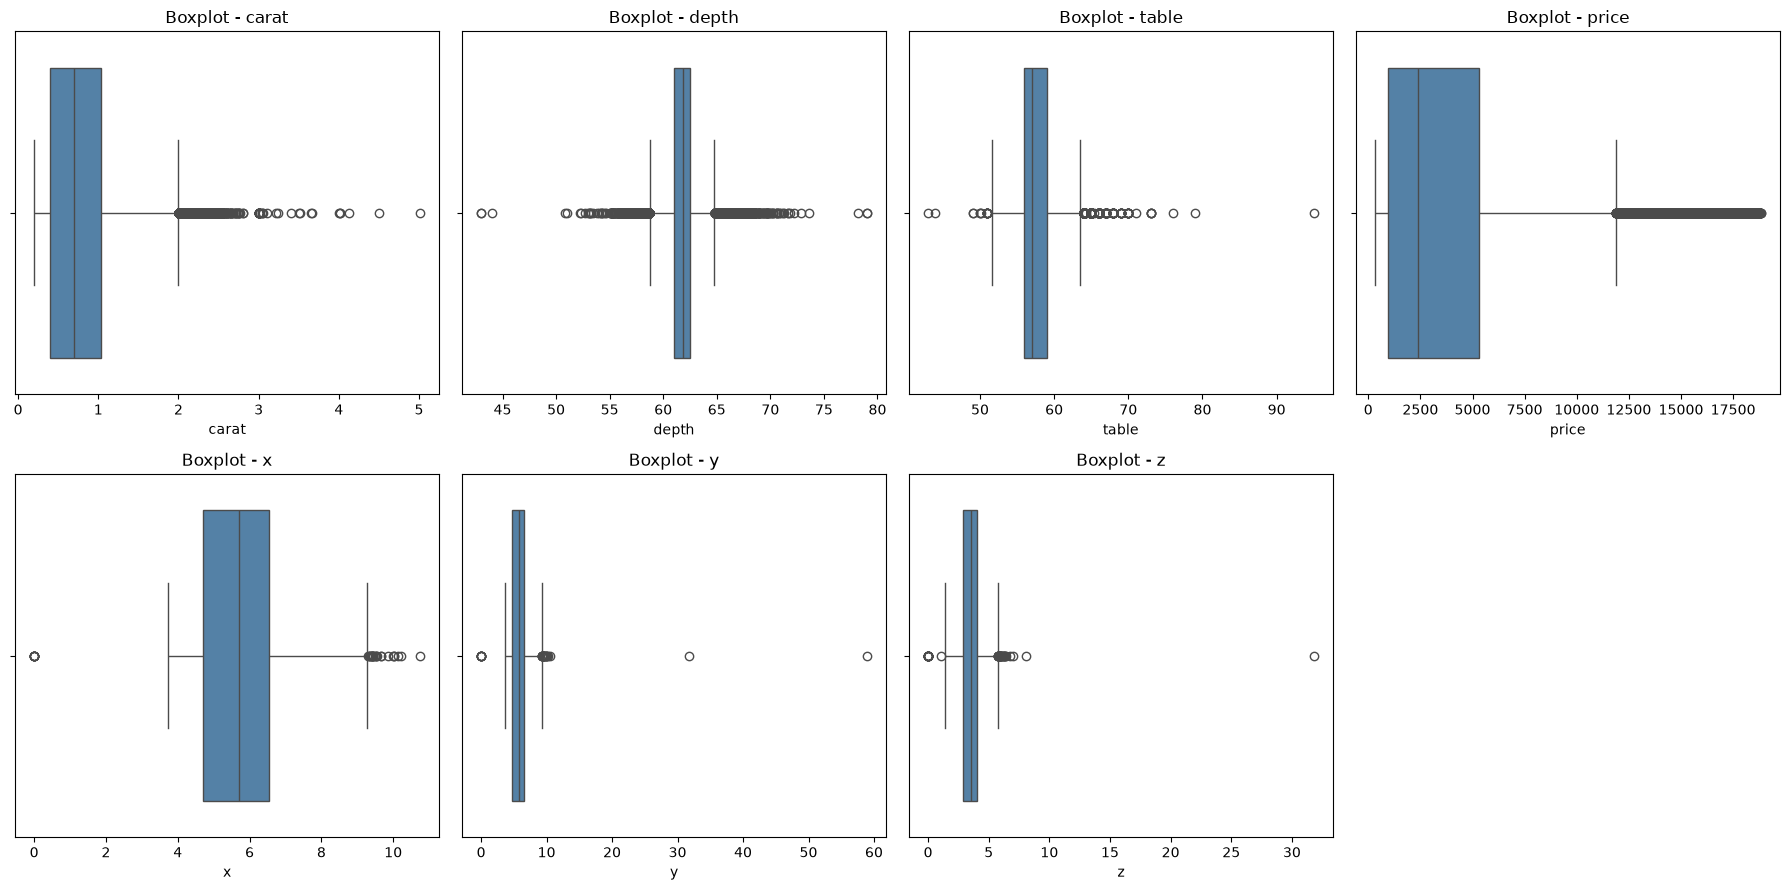

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for coluna, ax in zip(colunas_numericas, axes.flat):
    sns.boxplot(x=diamonds[coluna], ax=ax, color="steelblue")
    ax.set_title(f"Boxplot - {coluna}")
for ax in axes.flat[len(colunas_numericas):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

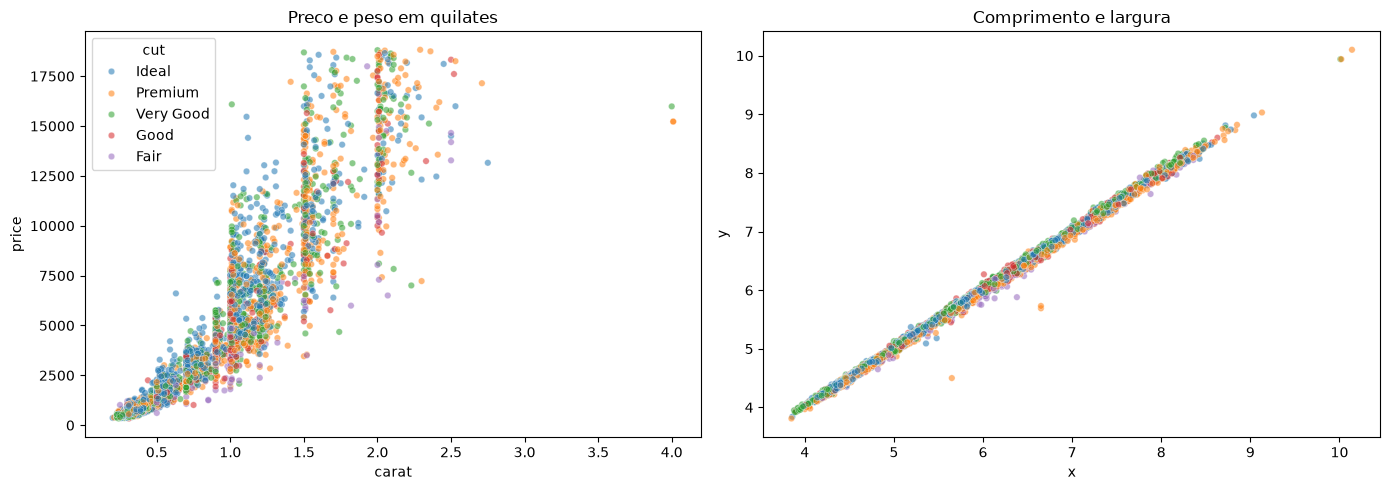

In [9]:
amostra = diamonds.sample(n=min(5000, len(diamonds)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=amostra, x="carat", y="price", hue="cut", alpha=0.55, s=22, ax=axes[0])
axes[0].set_title("Preco e peso em quilates")
sns.scatterplot(data=amostra, x="x", y="y", hue="cut", alpha=0.55, s=22, legend=False, ax=axes[1])
axes[1].set_title("Comprimento e largura")
plt.tight_layout()
plt.show()

### CLASSIFICAÇÃO: ERRO DE REGISTRO OU VALOR EXTREMO LEGÍTIMO?

Critério usado: dimensões `x`, `y` ou `z` iguais a zero ou negativas são inconsistências físicas e devem ser tratadas como prováveis erros ou dados inválidos. Já um preço ou peso alto não é considerado erro apenas por ultrapassar um limite estatístico. Verifico se ele mantém uma relação plausível com os quilates e as dimensões. Um valor extremo coerente com as demais características pode ser raro, mas legítimo. Z-score e IQR servem para apontar casos que merecem investigação, não para decidir automaticamente pela exclusão.

In [10]:
exemplos_price = pd.concat([
    diamonds.loc[mascara_z["price"], ["carat", "price", "cut", "x", "y", "z"]]
        .assign(metodo="Z-score"),
    diamonds.loc[mascara_iqr["price"], ["carat", "price", "cut", "x", "y", "z"]]
        .assign(metodo="IQR")
]).drop_duplicates()
exemplos_price.sort_values("price", ascending=False).head(10)

,carat,price,cut,x,y,z,metodo
27749,2.29,18823,Premium,8.50,8.47,5.16,IQR
27749,2.29,18823,Premium,8.50,8.47,5.16,Z-score
27748,2.00,18818,Very Good,7.90,7.97,5.04,Z-score
27748,2.00,18818,Very Good,7.90,7.97,5.04,IQR
27747,1.51,18806,Ideal,7.37,7.41,4.56,IQR
27747,1.51,18806,Ideal,7.37,7.41,4.56,Z-score
27746,2.07,18804,Ideal,8.20,8.13,5.11,Z-score
27746,2.07,18804,Ideal,8.20,8.13,5.11,IQR
27745,2.00,18803,Very Good,7.95,8.00,5.01,IQR
27745,2.00,18803,Very Good,7.95,8.00,5.01,Z-score


### TRATAMENTO E IMPACTO NA DISTRIBUIÇÃO DE `price`

Para comparar as estratégias em condições equivalentes, o tratamento é aplicado à coluna `price`, usando os limites IQR calculados para ela. A remoção demonstra o custo de excluir preços fora dos limites; o capping limita esses preços; e `log1p` comprime a cauda sem excluir registros. Essas operações são demonstrações: a decisão final depende do objetivo e da investigação dos registros.

In [11]:
price_q1 = diamonds["price"].quantile(0.25)
price_q3 = diamonds["price"].quantile(0.75)
price_iqr = price_q3 - price_q1
limite_inferior_price = price_q1 - 1.5 * price_iqr
limite_superior_price = price_q3 + 1.5 * price_iqr

sem_outliers_price = diamonds.loc[
    diamonds["price"].between(limite_inferior_price, limite_superior_price)
].copy()

price_capped = diamonds.copy()
price_capped["price"] = price_capped["price"].clip(
    lower=limite_inferior_price, upper=limite_superior_price
)

price_log = diamonds.copy()
price_log["price_log1p"] = np.log1p(price_log["price"])

print("Linhas no original:", len(diamonds))
print("Linhas apos remocao de outliers de price:", len(sem_outliers_price))
print("Linhas com capping:", len(price_capped))
print("Linhas com transformacao log:", len(price_log))

Linhas no original: 53940
Linhas apos remocao de outliers de price: 50400
Linhas com capping: 53940
Linhas com transformacao log: 53940


In [12]:
resumo_tratamentos = pd.DataFrame({
    "original": diamonds["price"].describe(),
    "remocao": sem_outliers_price["price"].describe(),
    "capping": price_capped["price"].describe(),
    "log1p": price_log["price_log1p"].describe()
})
resumo_tratamentos

,original,remocao,capping,log1p
count,53940.000000,50400.000000,53940.000000,53940.000000
mean,3932.799722,3159.460833,3732.145690,7.787424
std,3989.439738,2764.700316,3436.769344,1.014111
min,326.000000,326.000000,326.000000,5.789960
25%,950.000000,911.000000,950.000000,6.857514
50%,2401.000000,2155.000000,2401.000000,7.784057
75%,5324.250000,4669.000000,5324.250000,8.580215
max,18823.000000,11883.000000,11885.625000,9.842888


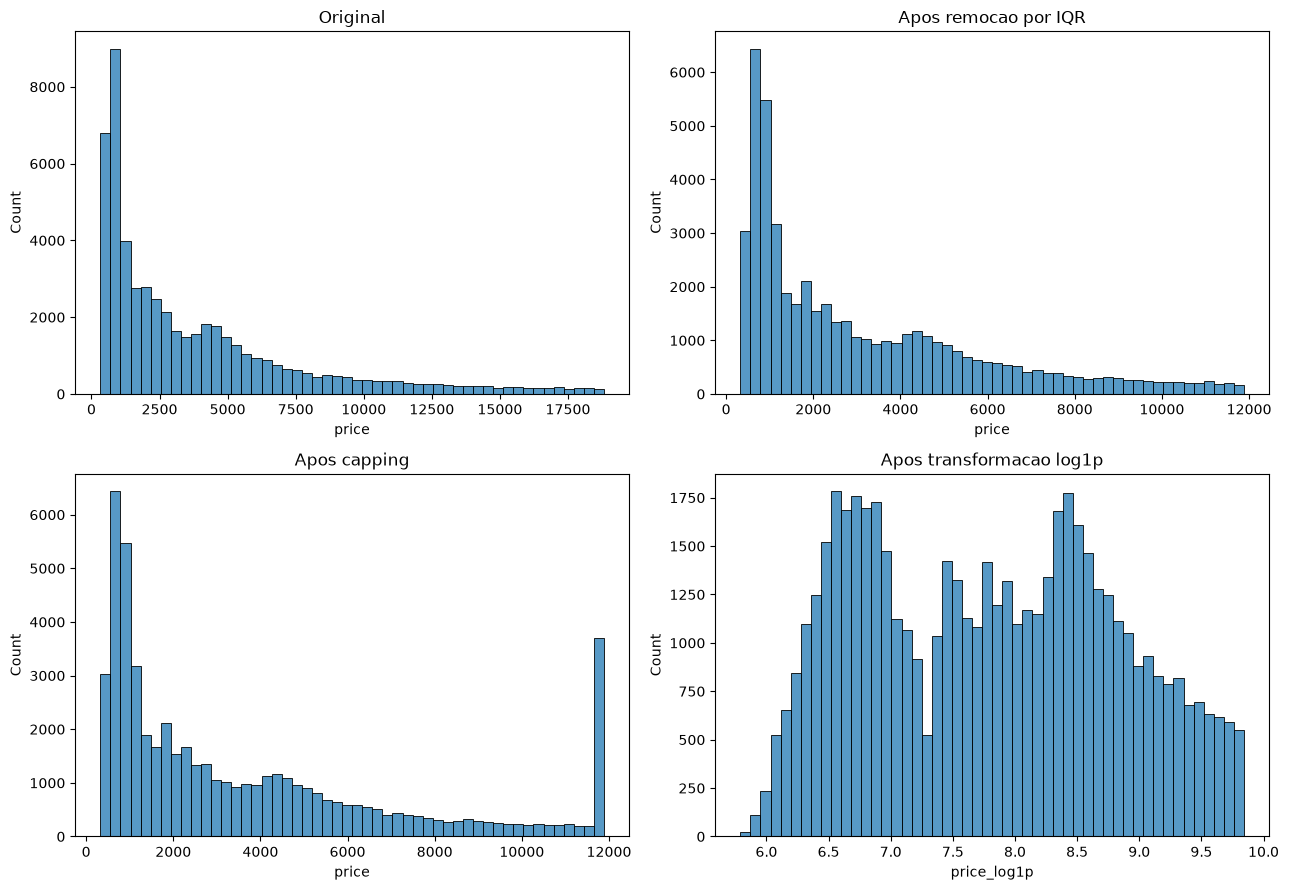

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(diamonds["price"], bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Original")
sns.histplot(sem_outliers_price["price"], bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Apos remocao por IQR")
sns.histplot(price_capped["price"], bins=50, ax=axes[1, 0])
axes[1, 0].set_title("Apos capping")
sns.histplot(price_log["price_log1p"], bins=50, ax=axes[1, 1])
axes[1, 1].set_title("Apos transformacao log1p")
plt.tight_layout()
plt.show()

### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **O Z-score parte de uma suposição sobre a forma da distribuição. Qual? Essa suposição vale para `price`? Mostre com um gráfico.**

   O Z-score é mais fácil de interpretar quando a variável tem distribuição aproximadamente normal, simétrica e sem caudas muito pesadas. `price` não apresenta esse formato: há uma cauda longa à direita, visível no histograma original acima. Por isso, o limite de três desvios-padrão pode não descrever bem o que é incomum para essa variável.

2. **Um diamante de mais de 4 quilates é um outlier a ser removido ou um diamante raro? Como o objetivo da análise muda essa resposta?**

   Um diamante acima de 4 quilates é raro, mas isso, por si só, não prova que seja um erro. Para estimar preços comuns ou treinar um modelo voltado ao mercado típico, pode ser útil comparar os resultados com e sem esses casos, ou usar métodos resistentes a extremos. Se o objetivo for encontrar diamantes raros e de alto valor, removê-los apagaria justamente os casos mais importantes. Primeiro, eu verificaria se peso, preço e dimensões são coerentes.

3. **Dê um exemplo de situação em que remover outliers esconderia exatamente aquilo que o negócio quer descobrir.**

   Em uma seguradora, transações muito altas podem ser raras e aparecer como outliers, mas podem representar fraude ou sinistros de grande impacto. Removê-las antes da análise esconderia os eventos que a equipe quer detectar.

# Exercício 5 — Projeto Integrado de Limpeza

## Dirty E-Commerce Data: eletrônicos e brinquedos

Os arquivos escolhidos são `us-shein-electronics-4395.csv` e `us-shein-toys_and_games-3577.csv`.

### IMPORTAÇÕES E PERGUNTA DE NEGÓCIO

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import re

**Pergunta de negócio:** Como se comparam os preços anunciados e os descontos de eletrônicos e brinquedos? Dentro de cada catálogo, quais subcategorias têm menor preço mediano?


### CARREGAMENTO DOS ARQUIVOS

In [15]:
arquivos = {
    "eletronicos": "../data/us-shein-electronics-4395.csv",
    "brinquedos": "../data/us-shein-toys_and_games-3577.csv"
}
dados_brutos = {
    nome: pd.read_csv(caminho, dtype="string")
    for nome, caminho in arquivos.items()
}
{nome: df.shape for nome, df in dados_brutos.items()}

{'eletronicos': (4394, 9), 'brinquedos': (3576, 6)}

### DIAGNÓSTICO INICIAL — ANTES DE CORRIGIR

Os dois arquivos somam 7.970 registros: 4.394 de eletrônicos e 3.576 de brinquedos. No diagnóstico bruto, os campos estão como texto; preços e descontos incluem símbolos, e há campos opcionais vazios. A contagem de duplicatas exatas é feita linha a linha, sem presumir que nomes parecidos representem o mesmo produto.

In [16]:
def diagnostico_inicial(df, nome):
    total_celulas = df.shape[0] * df.shape[1]
    resumo = {
        "catalogo": nome,
        "linhas": len(df),
        "colunas": df.shape[1],
        "ausentes_pct": 100 * df.isna().sum().sum() / total_celulas if total_celulas else 0,
        "duplicatas_exatas": int(df.duplicated().sum()),
        "tipos": df.dtypes.astype(str).value_counts().to_dict()
    }
    ausentes_por_coluna = df.isna().sum().sort_values(ascending=False)
    return resumo, ausentes_por_coluna

resumos_iniciais = {}
for nome, df in dados_brutos.items():
    resumos_iniciais[nome], ausentes_coluna = diagnostico_inicial(df, nome)
    print(f"\n{nome}: {resumos_iniciais[nome]}")
    display(ausentes_coluna[ausentes_coluna > 0].to_frame("ausentes"))
    display(df.head(3))


eletronicos: {'catalogo': 'eletronicos', 'linhas': 4394, 'colunas': 9, 'ausentes_pct': np.float64(59.161482830121884), 'duplicatas_exatas': 34, 'tipos': {'string': 9}}


,ausentes
goods-title-link--jump,4356
goods-title-link--jump href,4356
rank-title,3647
rank-sub,3647
color-count,3256
discount,2869
selling_proposition,1227
goods-title-link,38


,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,discount,selling_proposition,color-count,goods-title-link
0,10pcs Random Color Data Cable Organizer,https://us.shein.com/10pcs-Random-Color-Data-C...,#10 Best Sellers,in Cable Storage,$1.36,-20%,<NA>,<NA>,<NA>
1,3pcs Anti Glare Tempered Glass Front Film Phon...,https://us.shein.com/3pcs-Anti-Glare-Tempered-...,#1 Best Sellers,in Screen Protectors,$2.32,-20%,<NA>,<NA>,<NA>
2,"Universal Waterproof Phone Pouch, Waterproof P...",https://us.shein.com/Universal-Waterproof-Phon...,<NA>,<NA>,$1.70,<NA>,600+ sold recently,<NA>,<NA>



brinquedos: {'catalogo': 'brinquedos', 'linhas': 3576, 'colunas': 6, 'ausentes_pct': np.float64(43.51696495152871), 'duplicatas_exatas': 148, 'tipos': {'string': 6}}


,ausentes
rank-title,2993
rank-sub,2993
discount,2066
selling_proposition,1273
goods-title-link,12


,rank-title,rank-sub,price,selling_proposition,discount,goods-title-link
0,#6 Best Sellers,in Kids Drawing & Painting Supplies,$2.90,<NA>,<NA>,<NA>
1,<NA>,<NA>,$2.40,600+ sold recently,<NA>,<NA>
2,<NA>,<NA>,$3.80,1.2k+ sold recently,<NA>,<NA>


### FUNÇÕES REUTILIZÁVEIS DO PIPELINE

In [ ]:
def corrigir_tipos(df, catalogo):
    saida = df.copy()
    titulos = [c for c in ["goods-title-link--jump", "goods-title-link"] if c in saida]
    nome_produto = saida[titulos[0]] if titulos else pd.Series(pd.NA, index=saida.index, dtype="string")
    for coluna in titulos[1:]:
        nome_produto = nome_produto.fillna(saida[coluna])
    saida["product_name"] = nome_produto

    saida["catalog"] = catalogo
    saida["subcategory"] = saida["rank-sub"] if "rank-sub" in saida else pd.NA

    texto_preco = saida["price"].astype("string").str.replace(r"[^0-9,.-]", "", regex=True)
    texto_preco = texto_preco.str.replace(",", "", regex=False)
    saida["price_usd"] = pd.to_numeric(texto_preco, errors="coerce")

    if "discount" in saida:
        desconto = saida["discount"].astype("string").str.extract(r"(-?\d+(?:\.\d+)?)", expand=False)
        saida["discount_pct"] = pd.to_numeric(desconto, errors="coerce").abs()
    if "rank-title" in saida:
        posicao = saida["rank-title"].astype("string").str.extract(r"#\s*(\d+)", expand=False)
        saida["rank_position"] = pd.to_numeric(posicao, errors="coerce")
    if "selling_proposition" in saida:
        vendas = saida["selling_proposition"].astype("string").str.extract(
            r"(?i)([\d,.]+)\s*([k]?)", expand=True
        )
        numero = pd.to_numeric(vendas[0].str.replace(",", "", regex=False), errors="coerce")
        multiplicador = vendas[1].str.lower().eq("k").map({True: 1000, False: 1})
        saida["sales_recently_min"] = numero * multiplicador
    if "color-count" in saida:
        saida["color_count"] = pd.to_numeric(saida["color-count"], errors="coerce")

    colunas_originais = [
        "goods-title-link--jump", "goods-title-link--jump href", "goods-title-link",
        "rank-title", "rank-sub", "price", "discount", "selling_proposition", "color-count"
    ]
    return saida.drop(columns=[c for c in colunas_originais if c in saida])


def tratar_ausentes(df):
    saida = df.copy()
    for coluna in saida.select_dtypes(include=["string", "object"]).columns:
        saida[coluna] = saida[coluna].replace(r"^\s*$", np.nan, regex=True)
    if "subcategory" in saida:
        saida["subcategory"] = saida["subcategory"].fillna("Não informada")
    essenciais = [c for c in ["product_name", "price_usd"] if c in saida]
    return saida.dropna(subset=essenciais).copy()


def padronizar_textos(df):
    saida = df.copy()
    for coluna in saida.select_dtypes(include=["string", "object"]).columns:
        saida[coluna] = saida[coluna].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    for coluna in ["catalog", "subcategory", "product_name"]:
        if coluna in saida:
            saida[coluna] = saida[coluna].str.casefold()
    return saida


def tratar_duplicatas(df):
    return df.drop_duplicates().copy()


def tratar_outliers(df):
    saida = df.copy()
    saida["price_outlier_iqr"] = False
    saida["price_capped"] = saida["price_usd"]
    for _, indices in saida.groupby("catalog").groups.items():
        valores = saida.loc[indices, "price_usd"]
        q1, q3 = valores.quantile([0.25, 0.75])
        iqr = q3 - q1
        inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        saida.loc[indices, "price_outlier_iqr"] = (valores < inferior) | (valores > superior)
        saida.loc[indices, "price_capped"] = valores.clip(inferior, superior)
    return saida


def criar_features(df):
    saida = df.copy()
    saida["price_band"] = pd.cut(
        saida["price_usd"],
        bins=[-np.inf, 5, 20, 50, np.inf],
        labels=["ate_usd_5", "usd_5_a_20", "usd_20_a_50", "acima_usd_50"]
    )
    return saida


def limpar_catalogo(df, catalogo):
    saida = corrigir_tipos(df, catalogo)
    saida = tratar_ausentes(saida)
    saida = padronizar_textos(saida)
    saida = tratar_duplicatas(saida)
    saida = tratar_outliers(saida)
    return criar_features(saida)

### EXECUÇÃO DO PIPELINE

In [18]:
dados_limpos = {
    nome: limpar_catalogo(df, nome)
    for nome, df in dados_brutos.items()
}
{nome: df.shape for nome, df in dados_limpos.items()}

{'eletronicos': (4358, 11), 'brinquedos': (3416, 10)}

### TABELA ANTES X DEPOIS

In [19]:
def indicadores_qualidade(df, nome, etapa):
    total_celulas = df.shape[0] * df.shape[1]
    return {
        "catalogo": nome,
        "etapa": etapa,
        "linhas": len(df),
        "colunas": df.shape[1],
        "ausentes_pct": round(100 * df.isna().sum().sum() / total_celulas, 2) if total_celulas else 0,
        "duplicatas_exatas": int(df.duplicated().sum()),
        "tipos_das_colunas": "; ".join(f"{col}: {tipo}" for col, tipo in df.dtypes.astype(str).items())
    }

comparacao_qualidade = []
for nome in dados_brutos:
    comparacao_qualidade.append(indicadores_qualidade(dados_brutos[nome], nome, "antes"))
    comparacao_qualidade.append(indicadores_qualidade(dados_limpos[nome], nome, "depois"))
qualidade = pd.DataFrame(comparacao_qualidade)
qualidade

,catalogo,etapa,linhas,colunas,ausentes_pct,duplicatas_exatas,tipos_das_colunas
0,eletronicos,antes,4394,9,59.16,34,goods-title-link--jump: string; goods-title-li...
1,eletronicos,depois,4358,11,22.74,0,product_name: string; catalog: string; subcate...
2,brinquedos,antes,3576,6,43.52,148,rank-title: string; rank-sub: string; price: s...
3,brinquedos,depois,3416,10,17.69,0,product_name: string; catalog: string; subcate...


### VISUALIZAÇÕES: COMPLETUDE E TRATAMENTO DE PREÇOS EXTREMOS

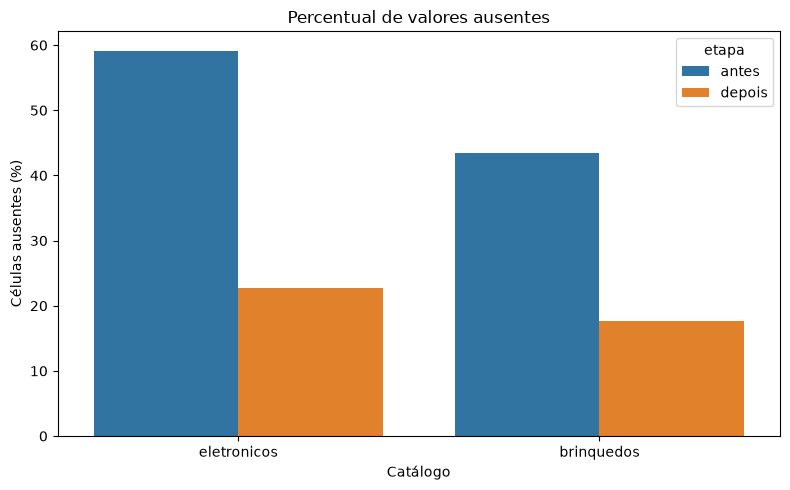

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=qualidade, x="catalogo", y="ausentes_pct", hue="etapa", ax=ax)
ax.set_title("Percentual de valores ausentes")
ax.set_ylabel("Células ausentes (%)")
ax.set_xlabel("Catálogo")
plt.tight_layout()
plt.show()

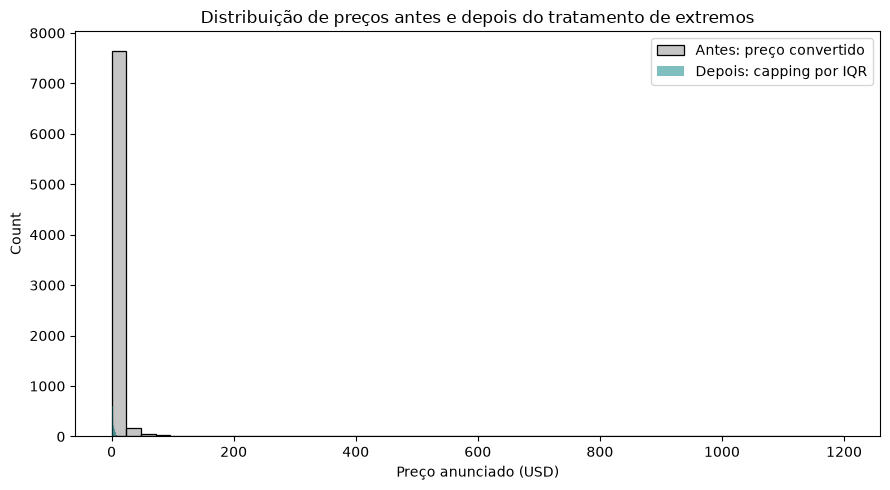

In [21]:
precos_antes = []
for df in dados_brutos.values():
    texto = df["price"].astype("string").str.replace(r"[^0-9,.-]", "", regex=True)
    valores = pd.to_numeric(texto.str.replace(",", "", regex=False), errors="coerce").dropna()
    precos_antes.extend(valores.tolist())
precos_depois = pd.concat([df["price_capped"] for df in dados_limpos.values()], ignore_index=True)

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(precos_antes, bins=50, color="gray", alpha=0.45, label="Antes: preço convertido", ax=ax)
sns.histplot(precos_depois, bins=50, color="teal", alpha=0.5, label="Depois: capping por IQR", ax=ax)
ax.set_title("Distribuição de preços antes e depois do tratamento de extremos")
ax.set_xlabel("Preço anunciado (USD)")
ax.legend()
plt.tight_layout()
plt.show()

### RELATÓRIO DAS DECISÕES

- **Tipos:** `price` foi convertido de texto com cifrão para número. Desconto, posição no ranking, contagem de cores e indicação de vendas recentes foram convertidos quando disponíveis. O texto `1.3k+` vira uma estimativa mínima de 1.300 vendas, não uma contagem exata.
- **Ausências:** espaços vazios foram reconhecidos como ausentes. Título e preço são essenciais, então registros sem esses campos são removidos. Subcategoria ausente recebe `não informada`. Desconto e ranking permanecem ausentes quando não foram publicados; preencher esses campos com zero confundiria desconhecido com inexistente.
- **Duplicatas:** linhas idênticas foram removidas após a padronização dos textos. Registros com nome igual, mas outros campos diferentes, foram preservados porque podem refletir variações ou capturas distintas.
- **Textos:** espaços repetidos foram reduzidos e a caixa foi uniformizada nos nomes e subcategorias. O título foi combinado a partir das duas colunas alternativas presentes no arquivo de eletrônicos.
- **Extremos:** o IQR por catálogo gera a marca `price_outlier_iqr` e uma coluna limitada `price_capped`. O preço original convertido foi preservado para auditoria; preços altos não foram apagados automaticamente, pois podem corresponder a produtos legítimos.
- **Nova coluna:** `price_band` classifica os preços em faixas úteis para comparar produtos acessíveis e mais caros.

As visualizações comparam a proporção de ausências e a distribuição de preços antes e depois. A tabela de qualidade registra dimensão, ausências, duplicatas e tipos por arquivo em cada etapa.

### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **Qual problema foi o mais difícil de perceber? Por que ele passaria despercebido em uma análise rápida?**

   O nome do produto de eletrônicos está dividido entre duas colunas: uma tem muitos vazios, mas a outra contém a maior parte dos títulos. Uma inspeção rápida poderia levar a descartar milhares de linhas por parecerem sem nome, sem perceber que bastava combinar as duas fontes.

2. **A ordem das etapas importa? Dê um exemplo em que tratar outliers antes dos ausentes, ou vice-versa, mudaria o resultado.**

   Sim. Se um preço ausente fosse preenchido com zero antes de calcular o IQR, ele poderia reduzir artificialmente os quartis e alterar os limites usados para sinalizar ou limitar extremos. Por isso, primeiro converto os preços, reconheço os ausentes e removo apenas registros sem preço; depois calculo o IQR com os valores observados.

3. **Se a pergunta de negócio fosse outra, qual decisão de limpeza você mudaria?**

   Se a pergunta fosse identificar exatamente os produtos mais caros, eu não usaria `price_capped` para ordenar ou modelar, porque o capping reduz os maiores valores ao limite superior. Usaria `price_usd`, que foi preservado, investigaria cada extremo e manteria os casos confirmados como legítimos.